# Tối ưu F1 bằng các kết quả đã huấn luyện

Notebook này không huấn luyện lại MiniLM. Nó chọn trọng số trộn MiniLM và TF-IDF Logistic Regression cùng ngưỡng bằng OOF train,
sau đó đánh giá cấu hình đã cố định trên test. Một mức tăng trên Mac không bảo đảm tăng trên phiên Kaggle khác.

Nếu tiếp tục đúng session cũ, chỉ Run All. Nếu mở session mới, chọn **Add Input** và thêm **output của notebook Kaggle đã chạy**
(thư mục Project có reports/experiments, reports/fine_tuning và models). Bản ZIP cũ 171,7 MB không có OOF của LR,
nên riêng ZIP đó chưa đủ. Notebook tự tìm bộ kết quả cũ và chỉ copy các tệp cần thiết sang /kaggle/working.
GPU không bắt buộc; phần inference kiểm tra model dùng CPU. Giữ riêng các số đo cũ và mới.


In [1]:
import os,sys,json,shutil,subprocess,importlib.util
from pathlib import Path
from IPython.display import display,Image
IS_KAGGLE=Path('/kaggle/working').exists()
PROJECT=Path(os.environ.get('FORUM_PROJECT_DIR','/kaggle/working/Project' if IS_KAGGLE else str(Path.cwd()/'Project'))).resolve()
needed=Path('reports/experiments/oof_stanford_tfidf_logreg.csv')
if not (PROJECT/needed).exists():
    previous_project=os.environ.get('FORUM_PREVIOUS_PROJECT_DIR')
    matches=([Path(previous_project)/needed] if previous_project else
             (list(Path('/kaggle/input').rglob('oof_stanford_tfidf_logreg.csv')) if IS_KAGGLE else []))
    if len(matches)!=1:
        raise RuntimeError('Attach exactly one previous notebook output containing Project/reports/experiments/oof_stanford_tfidf_logreg.csv. No encoder retraining is performed.')
    previous=matches[0].parents[2]
    for source in ['upenn','stanford']:
        for relative in [f'reports/experiments/oof_{source}_tfidf_logreg.csv',
                         *[f'reports/experiments/predictions_{source}_{target}_tfidf_logreg.csv' for target in ['upenn','stanford']],
                         f'models/{source}__tfidf_logreg.joblib']:
            target=PROJECT/relative;target.parent.mkdir(parents=True,exist_ok=True);shutil.copyfile(previous/relative,target)
        for relative in [f'reports/fine_tuning/{source}',f'models/urgency_minilm_{source}']:
            shutil.copytree(previous/relative,PROJECT/relative,dirs_exist_ok=True)
    (PROJECT/'reports/fine_tuning/results.json').write_text(json.dumps([
        r for source in ['upenn','stanford'] for r in json.loads((PROJECT/f'reports/fine_tuning/{source}/test_results.json').read_text())]))
for folder in ['scripts','reports/figures','.cache/tmp']:(PROJECT/folder).mkdir(parents=True,exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT),HF_HOME=str(PROJECT/'.cache/huggingface'),
    MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),TMPDIR=str(PROJECT/'.cache/tmp'),
    OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',TOKENIZERS_PARALLELISM='false')
required={'torch':'torch>=2.8','transformers':'transformers>=4.55,<6','sklearn':'scikit-learn>=1.6,<2','matplotlib':'matplotlib','joblib':'joblib'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:subprocess.run([sys.executable,'-m','pip','install',*missing],check=True)
print('Existing experiment folder:',PROJECT)
print('No encoder training. Only OOF selection, test evaluation, packaging and offline inference.')


Existing experiment folder: /Users/nhaterik/lastyear/machine/Project
No encoder training. Only OOF selection, test evaluation, packaging and offline inference.


## prepare_data.py


In [2]:
(PROJECT/"scripts"/'prepare_data.py').write_text(r'''"""Download and audit two pinned public datasets using only Python's standard library."""
from __future__ import annotations

import argparse
import csv
import hashlib
import html
import json
import math
import re
import subprocess
import unicodedata
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
REVISION = "ebf3695f01d2dec197253eb89499f4835bb7d0fa"
FILES = {"upenn": "All_Courses_REDACTED_CODED.csv", "stanford": "Stanford.csv"}
EXPECTED_SHA256 = {
    "upenn": "403301d079abcea1acc318b7a63f766658350dbc0e85eead79f7befc65aa48c3",
    "stanford": "31e8885939604a20cd0a903d1e5ebca811b850530b8e9ed5169e1936628142f2",
}
FIELDS = ["post_id", "source", "source_row", "source_id", "source_time", "source_course_type", "text_raw",
          "text_clean", "urgency", "priority", "word_count", "text_sha256"]
TAG = re.compile(r"</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>", re.I)


def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()


def dump_json(path: Path, data) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8")


def clean_text(text: str) -> str:
    return " ".join(TAG.sub(" ", unicodedata.normalize("NFC", html.unescape(text))).split())


def percentile(values, fraction):
    ordered = sorted(values)
    index = (len(ordered) - 1) * fraction
    low = math.floor(index)
    high = math.ceil(index)
    return round(ordered[low] + (ordered[high] - ordered[low]) * (index - low), 2)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--download", action="store_true", help="Download missing raw files, never replace existing files")
    args = parser.parse_args()
    rejected, datasets, audit = [], {}, {"source_revision": REVISION, "label_rule": "priority = int(urgency > 4)", "datasets": {}}
    for source, filename in FILES.items():
        path = ROOT / "data/raw" / filename
        url = f"https://raw.githubusercontent.com/pcla-code/forum-posts-urgency/{REVISION}/{filename}"
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            if not args.download:
                raise SystemExit(f"Thiếu {path.name}. Chạy bash Project/run.sh --download từ machine.")
            print(f"Đang tải {source} từ commit {REVISION[:12]}...", flush=True)
            temporary = path.with_suffix(".csv.part")
            try:
                subprocess.run(["curl", "-q", "--fail", "--location", "--silent", "--show-error",
                                "--connect-timeout", "10", "--max-time", "120", "--retry", "1",
                                "--output", str(temporary), url], check=True)
                temporary.replace(path)
            finally:
                temporary.unlink(missing_ok=True)
        if sha256(path) != EXPECTED_SHA256[source]:
            raise ValueError(f"SHA-256 tệp gốc không khớp phiên bản cố định: {filename}")
        groups = defaultdict(list)
        counts = Counter()
        with path.open(encoding="utf-8-sig", newline="") as handle:
            reader = csv.DictReader(handle)
            if not {"post_text", "Urgency_1_7"}.issubset(reader.fieldnames or []):
                raise ValueError(f"Schema không phù hợp: {path.name}")
            columns = reader.fieldnames
            for row_number, raw in enumerate(reader, start=2):
                counts["raw_rows"] += 1
                reason = None
                if None in raw or raw.get("post_text") is None or raw.get("Urgency_1_7") is None:
                    reason = "malformed_or_missing_fields"
                try:
                    urgency = float(raw.get("Urgency_1_7") or "nan")
                except (TypeError, ValueError):
                    urgency = float("nan")
                if reason is None and (not math.isfinite(urgency) or not 1 <= urgency <= 7):
                    reason = "missing_or_invalid_urgency"
                text = clean_text(raw.get("post_text") or "")
                if reason is None and not text:
                    reason = "empty_text"
                if reason:
                    counts[reason] += 1
                    rejected.append({"source": source, "source_row": row_number, "reason": reason})
                    continue
                counts["valid_rows"] += 1
                key = hashlib.sha256(text.casefold().encode("utf-8")).hexdigest()
                groups[key].append({"post_id": f"{source}_{row_number:06d}", "source": source,
                                    "source_row": row_number, "source_id": raw.get("id", ""),
                                    "source_time": raw.get("post_time", ""),
                                    "source_course_type": raw.get("CourseType", ""), "text_raw": raw["post_text"],
                                    "text_clean": text, "urgency": urgency, "priority": int(urgency > 4),
                                    "word_count": len(text.split()), "text_sha256": key})
        retained = []
        for rows in groups.values():
            conflict = len({row["priority"] for row in rows}) > 1
            if conflict:
                counts["conflicting_groups"] += 1
            discarded = rows if conflict else rows[1:]
            reason = "conflicting_binary_labels" if conflict else "duplicate_within_source"
            counts[reason] += len(discarded)
            rejected.extend({"source": source, "source_row": row["source_row"], "reason": reason} for row in discarded)
            if not conflict:
                retained.append(rows[0])
        counts["after_within_source_dedup"] = len(retained)
        counts["cross_source_duplicates"] = 0
        datasets[source] = sorted(retained, key=lambda row: row["source_row"])
        audit["datasets"][source] = {"raw_file": str(path.relative_to(ROOT)), "url": url,
                                       "raw_sha256": sha256(path), "raw_bytes": path.stat().st_size,
                                       "columns": columns, "counts": dict(counts)}

    upenn_keys = {row["text_sha256"] for row in datasets["upenn"]}
    unique_stanford = []
    for row in datasets["stanford"]:
        if row["text_sha256"] in upenn_keys:
            audit["datasets"]["stanford"]["counts"]["cross_source_duplicates"] += 1
            rejected.append({"source": "stanford", "source_row": row["source_row"], "reason": "duplicate_across_sources"})
        else:
            unique_stanford.append(row)
    datasets["stanford"] = unique_stanford

    for source, rows in datasets.items():
        if not rows:
            raise ValueError(f"Không có dữ liệu hợp lệ: {source}")
        target = ROOT / "data/processed" / f"{source}.csv"
        target.parent.mkdir(parents=True, exist_ok=True)
        with target.open("w", encoding="utf-8", newline="") as handle:
            writer = csv.DictWriter(handle, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(rows)
        item = audit["datasets"][source]
        item["counts"]["final_rows"] = len(rows)
        item["label_counts"] = dict(Counter(str(row["priority"]) for row in rows))
        item["urgency_counts"] = dict(Counter(str(row["urgency"]) for row in rows))
        lengths = [row["word_count"] for row in rows]
        item["word_lengths"] = {"min": min(lengths), "median": percentile(lengths, .5),
                                 "p95": percentile(lengths, .95), "max": max(lengths),
                                 "mean": round(sum(lengths) / len(lengths), 2)}
        bounds = [(0, 25), (25, 50), (50, 100), (100, 200), (200, 400), (400, None)]
        item["length_histogram"] = {f"{lower + 1}–{upper}" if upper else f">{lower}":
            sum(length > lower and (upper is None or length <= upper) for length in lengths)
            for lower, upper in bounds}
        item["processed_file"] = str(target.relative_to(ROOT))
        item["processed_sha256"] = sha256(target)
        n_rejected = sum(record["source"] == source for record in rejected)
        assert item["counts"]["raw_rows"] == len(rows) + n_rejected
        assert all(row["text_clean"].strip() for row in rows)
        assert all(math.isfinite(row["urgency"]) and 1 <= row["urgency"] <= 7 for row in rows)
        assert all(row["priority"] == int(row["urgency"] > 4) for row in rows)
        assert len({row["text_sha256"] for row in rows}) == len(rows)
        assert {row["priority"] for row in rows} == {0, 1}
        print(f"{source}: raw={item['counts']['raw_rows']}, final={len(rows)}, priority={item['label_counts'].get('1', 0)}", flush=True)
    assert not ({row["text_sha256"] for row in datasets["upenn"]} &
                {row["text_sha256"] for row in datasets["stanford"]})
    audit["checks"] = {"rows_accounted_for": True, "nonempty_text": True, "labels_in_range": True,
                        "both_binary_classes_present": True, "no_exact_duplicates_within_sources": True,
                        "no_exact_duplicates_between_sources": True}
    dump_json(ROOT / "reports/data_audit.json", audit)
    with (ROOT / "reports/rejected_rows.csv").open("w", encoding="utf-8", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=["source", "source_row", "reason"])
        writer.writeheader()
        writer.writerows(sorted(rejected, key=lambda row: (row["source"], row["source_row"])))


if __name__ == "__main__":
    main()
''',encoding="utf-8")


9552

## train.py


In [3]:
(PROJECT/"scripts"/'train.py').write_text(r'''"""Reproducible source-only model selection and two-source held-out evaluation."""
from __future__ import annotations
import csv
import hashlib
import json
import platform
import sys
import time
from pathlib import Path
import joblib
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedKFold, StratifiedGroupKFold,
    train_test_split, GridSearchCV, cross_val_predict)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from prepare_data import dump_json, sha256

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/experiments'
SEED=42
ENCODER='sentence-transformers/all-MiniLM-L6-v2'
ENCODER_REV='1110a243fdf4706b3f48f1d95db1a4f5529b4d41'

def read_csv(path):
    with path.open(encoding='utf-8',newline='') as f:
        return list(csv.DictReader(f))

def write_csv(path, rows):
    path.parent.mkdir(parents=True,exist_ok=True)
    with path.open('w',encoding='utf-8',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(rows[0]))
        writer.writeheader();writer.writerows(rows)

def scores(model,x):
    if hasattr(model,'predict_proba'):
        return model.predict_proba(x)[:,1]
    return model.decision_function(x)

def metrics(y,s,t,ids):
    p=np.asarray(s)>=t
    matrix=confusion_matrix(y,p,labels=[0,1])
    order=np.lexsort((np.asarray(ids),-np.asarray(s)))
    k=min(20,len(y));found=int(np.asarray(y)[order[:k]].sum())
    return dict(precision=float(precision_score(y,p,zero_division=0)),recall=float(recall_score(y,p,zero_division=0)),
        f1=float(f1_score(y,p,zero_division=0)),macro_f1=float(f1_score(y,p,average='macro')),
        accuracy=float(accuracy_score(y,p)),average_precision=float(average_precision_score(y,s)),
        roc_auc=float(roc_auc_score(y,s)),precision_at_20=found/k,recall_at_20=found/int(np.sum(y)),
        top20_found=found,confusion_matrix=matrix.tolist(),test_size=len(y),positive_count=int(np.sum(y)))

def tune_threshold(y,s):
    precision,recall,thresholds=precision_recall_curve(y,s)
    f=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    # Highest threshold among exact F1 ties; no target test labels are used.
    index=np.flatnonzero(np.isclose(f,np.max(f),atol=1e-12,rtol=0))[-1]
    return float(thresholds[index]),float(f[index])

def embeddings(data):
    import torch
    from sentence_transformers import SentenceTransformer
    from huggingface_hub import snapshot_download
    snapshot=snapshot_download(ENCODER,revision=ENCODER_REV,
        allow_patterns=['*.json','*.txt','*.safetensors','1_Pooling/*'])
    device='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    torch.manual_seed(SEED)
    encoder=SentenceTransformer(snapshot,device=device)
    result={};info={'model':ENCODER,'revision':ENCODER_REV,'device':device,
        'snapshot':str(Path(snapshot).relative_to(ROOT)),'max_seq_length':encoder.max_seq_length,
        'dimension':(encoder.get_embedding_dimension() if hasattr(encoder,'get_embedding_dimension')
                     else encoder.get_sentence_embedding_dimension()),'sources':{}}
    for source,rows in data.items():
        path=ROOT/'.cache/embeddings'/f'{source}.npz';path.parent.mkdir(parents=True,exist_ok=True)
        fingerprint=sha256(ROOT/f'data/processed/{source}.csv')
        if path.exists():
            cached=np.load(path)
            if str(cached['fingerprint'])==fingerprint and str(cached['revision'])==ENCODER_REV:
                result[source]=cached['vectors'];info['sources'][source]={'cache_used':True};continue
        texts=[row['text_clean'] for row in rows]
        start=time.perf_counter()
        lengths=[]
        for i in range(0,len(texts),128):
            batch=encoder.tokenizer(texts[i:i+128],truncation=False,add_special_tokens=True)['input_ids']
            lengths.extend(map(len,batch))
        vectors=encoder.encode(texts,batch_size=64,normalize_embeddings=True,show_progress_bar=True).astype(np.float32)
        elapsed=time.perf_counter()-start
        np.savez_compressed(path,vectors=vectors,fingerprint=fingerprint,revision=ENCODER_REV)
        result[source]=vectors
        info['sources'][source]={'cache_used':False,'encoding_seconds':elapsed,
            'truncated_posts':sum(n>encoder.max_seq_length for n in lengths),'total':len(texts),
            'tokens_p95':float(np.percentile(lengths,95)),'tokens_max':max(lengths)}
        dump_json(OUT/'encoder_info.json',info)
    # Preserve original measured token/encoding stats when embeddings are reused.
    if (OUT/'encoder_info.json').exists():
        previous=json.loads((OUT/'encoder_info.json').read_text())
        for source,entry in info['sources'].items():
            if entry.get('cache_used') and source in previous.get('sources',{}):
                info['sources'][source]=previous['sources'][source]
    dump_json(OUT/'encoder_info.json',info)
    return result,info

def main():
    OUT.mkdir(parents=True,exist_ok=True)
    (ROOT/'models').mkdir(exist_ok=True)
    data={source:read_csv(ROOT/f'data/processed/{source}.csv') for source in ['upenn','stanford']}
    splits={};folds={};split_rows=[];split_info={}
    for source,rows in data.items():
        y=np.array([int(row['priority']) for row in rows]);indices=np.arange(len(rows))
        if source=='upenn':
            groups=np.array([row['source_id'] for row in rows])
            assert all(groups)
            train,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(indices,y,groups))
            folds[source]=list(StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train],groups[train]))
            assert not (set(groups[train]) & set(groups[test]))
            policy='GroupShuffleSplit by UPenn student id; 3-fold StratifiedGroupKFold for tuning'
        else:
            train,test=train_test_split(indices,test_size=.2,random_state=SEED,stratify=y)
            folds[source]=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,y[train]))
            policy='Stratified hold-out and 3-fold StratifiedKFold; author/thread IDs unavailable'
        for a,b in folds[source]:
            assert len(set(y[train[a]]))==2 and len(set(y[train[b]]))==2
        splits[source]=(train,test)
        split_info[source]={'policy':policy,'train':len(train),'test':len(test),
            'train_positives':int(y[train].sum()),'test_positives':int(y[test].sum()),
            'processed_sha256':sha256(ROOT/f'data/processed/{source}.csv')}
        train_set=set(train)
        assignments={int(i):('train' if i in train_set else 'test') for i in indices}
        split_rows.extend({'source':source,'post_id':row['post_id'],'split':assignments[i]} for i,row in enumerate(rows))
    write_csv(OUT/'split_ids.csv',split_rows);dump_json(OUT/'split_info.json',split_info)
    dump_json(OUT/'config.json',{'seed':SEED,'folds':3,'test_fraction':.2,'tfidf':{
        'ngram_range':[1,2],'min_df':2,'max_df':.98,'max_features':40000,'sublinear_tf':True},
        'threshold_rule':'Maximize positive F1 on source-only out-of-fold predictions; ties use largest threshold',
        'deployment_rule':'Best tuned OOF F1 among Stanford-trained models; independent test scores not used',
        'encoder_revision':ENCODER_REV,'data_hashes':{s:i['processed_sha256'] for s,i in split_info.items()}})
    results=[];cv_records=[]
    # Train TF-IDF first, so useful artifacts exist before downloading the optional encoder.
    embedded=None;encoder_info=None
    for representation in ['tfidf','minilm']:
        if representation=='minilm':
            embedded,encoder_info=embeddings(data)
        for source,rows in data.items():
            train,_=splits[source]
            y=np.array([int(row['priority']) for row in rows]);texts=np.array([row['text_clean'] for row in rows],dtype=object)
            x=texts if representation=='tfidf' else embedded[source]
            if representation=='tfidf':
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('svm',LinearSVC(class_weight='balanced',max_iter=10000,random_state=SEED),{'classifier__C':[.3,1.,3.]}),
                    ('nb',MultinomialNB(),{'classifier__alpha':[.1,.5,1.]}),
                    ('dummy',DummyClassifier(strategy='prior'),{})]
            else:
                candidates=[('logreg',LogisticRegression(class_weight='balanced',solver='liblinear',max_iter=2000,random_state=SEED),{'C':[.3,1.,3.,10.]})]
            for name,classifier,grid in candidates:
                slug=f'{representation}_{name}'
                print(f'TRAIN {source} / {slug}',flush=True)
                if representation=='tfidf':
                    model=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_df=.98,max_features=40000,
                        sublinear_tf=True,strip_accents='unicode',dtype=np.float32)),('classifier',classifier)])
                else:model=classifier
                start=time.perf_counter()
                search=GridSearchCV(model,grid,cv=folds[source],scoring='f1',n_jobs=1,refit=True,return_train_score=False)
                search.fit(x[train],y[train]);model=search.best_estimator_
                method='decision_function' if name=='svm' else 'predict_proba'
                oof=cross_val_predict(clone(model),x[train],y[train],cv=folds[source],method=method,n_jobs=1)
                oof=oof if name=='svm' else oof[:,1]
                default=0. if name=='svm' else .5
                threshold,oof_f1=tune_threshold(y[train],oof)
                if name=='dummy': threshold=default;oof_f1=float(f1_score(y[train],oof>=threshold,zero_division=0))
                elapsed=time.perf_counter()-start
                card={'source':source,'model':slug,'representation':representation,'name':name,
                    'threshold':threshold,'default_threshold':default,'cv_mean_f1':float(search.best_score_),
                    'cv_std_f1':float(search.cv_results_['std_test_score'][search.best_index_]),
                    'oof_tuned_f1':oof_f1,'best_params':search.best_params_,'training_seconds':elapsed}
                if representation=='minilm':card['encoder']=encoder_info
                cv_records.append(card)
                bundle={'model':model,'card':card}
                joblib.dump(bundle,ROOT/'models'/f'{source}__{slug}.joblib',compress=3)
                write_csv(OUT/f'oof_{source}_{slug}.csv',[{'post_id':rows[i]['post_id'],'label':int(y[i]),'score':float(s)} for i,s in zip(train,oof)])
                for target,target_rows in data.items():
                    _,test=splits[target]
                    test_x=np.array([row['text_clean'] for row in target_rows],dtype=object)[test] if representation=='tfidf' else embedded[target][test]
                    test_y=np.array([int(row['priority']) for row in target_rows])[test]
                    ids=[target_rows[i]['post_id'] for i in test]
                    start=time.perf_counter();s=scores(model,test_x);infer_seconds=time.perf_counter()-start
                    record={'train_source':source,'test_source':target,'model':slug,'threshold':threshold,
                        'training_seconds':elapsed,'inference_seconds':infer_seconds,**metrics(test_y,s,threshold,ids)}
                    record['default_threshold_metrics']=metrics(test_y,s,default,ids)
                    results.append(record)
                    prediction_rows=[]
                    for i,label,score in zip(test,test_y,s):
                        row=target_rows[i];pred=int(score>=threshold)
                        prediction_rows.append({'post_id':row['post_id'],'source':target,'source_id':row['source_id'],
                            'course_type':row['source_course_type'],'text':row['text_clean'],'urgency':row['urgency'],
                            'label':int(label),'predicted':pred,'score':float(score),
                            'error':'FN' if label==1 and pred==0 else 'FP' if label==0 and pred==1 else ''})
                    write_csv(OUT/f'predictions_{source}_{target}_{slug}.csv',prediction_rows)
                    print(f'  TEST {target}: P={record["precision"]:.3f} R={record["recall"]:.3f} F1={record["f1"]:.3f}',flush=True)
                dump_json(OUT/'results.json',results);dump_json(OUT/'cv_results.json',cv_records)
    selected=max((r for r in cv_records if r['source']=='stanford' and r['name']!='dummy'),key=lambda r:r['oof_tuned_f1'])
    dump_json(ROOT/'models/deployment.json',{'source':selected['source'],'model':selected['model'],
        'file':f"models/{selected['source']}__{selected['model']}.joblib",'selection_rule':'Stanford source training OOF F1 only',
        'oof_tuned_f1':selected['oof_tuned_f1'],'threshold':selected['threshold']})
    dump_json(OUT/'training_environment.json',{'python':sys.version,'sklearn':sklearn.__version__,
        'numpy':np.__version__,'platform':platform.platform(),'seed':SEED})
    print('DEPLOYMENT',selected['source'],selected['model'],flush=True)

if __name__=='__main__':main()
''',encoding="utf-8")


13597

## blend_trained_models.py


In [4]:
(PROJECT/"scripts"/'blend_trained_models.py').write_text(r'''"""Select a blend from saved source OOF predictions, then evaluate the fixed choice."""
import argparse,csv,hashlib,json
from pathlib import Path
import numpy as np
from sklearn.metrics import average_precision_score
from train import metrics,tune_threshold

ROOT=Path(__file__).resolve().parents[1];R=ROOT/'reports';OUT=R/'ensembles'

def read(path):
    with path.open(encoding='utf-8',newline='') as handle:rows=list(csv.DictReader(handle))
    result={r['post_id']:r for r in rows};assert len(result)==len(rows),'Duplicate post IDs'
    return result

def aligned(fine_path,lr_path):
    fine,lr=read(fine_path),read(lr_path)
    assert set(fine)==set(lr),'Mismatched split IDs'
    ids=sorted(fine);assert all(fine[i]['label']==lr[i]['label'] for i in ids),'Mismatched labels'
    y=np.array([int(fine[i]['label']) for i in ids])
    a=np.array([float(fine[i]['score']) for i in ids]);b=np.array([float(lr[i]['score']) for i in ids])
    return ids,y,a,b,fine

def dump(path,data):path.write_text(json.dumps(data,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')

def main():
    parser=argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--sources',nargs='+',choices=['upenn','stanford'],default=['upenn','stanford'])
    args=parser.parse_args();results=[]
    for source in args.sources:
        directory=OUT/source;directory.mkdir(parents=True,exist_ok=True)
        files=[R/f'fine_tuning/{source}/oof.csv',R/f'experiments/oof_{source}_tfidf_logreg.csv']
        ids,y,a,b,_=aligned(*files);candidates=[]
        for weight in np.linspace(0,1,21):
            scores=weight*a+(1-weight)*b;threshold,f1=tune_threshold(y,scores)
            candidates.append({'minilm_weight':float(weight),'tfidf_weight':float(1-weight),
                               'threshold':threshold,'oof_f1':f1,'oof_ap':float(average_precision_score(y,scores))})
        chosen=max(candidates,key=lambda c:(c['oof_f1'],c['oof_ap'],c['minilm_weight']))
        config={'train_source':source,**chosen,'selection':'source OOF F1; tie AP, then higher MiniLM weight',
                'validation_status':'Development diagnostics: base OOF predictions also participated in model/checkpoint selection; not nested CV.',
                'input_sha256':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in files}}
        # Persist the decision before opening either test prediction file.
        dump(directory/'selection.json',{'selected':config,'candidates':candidates})
        dump(directory/'decision_config.json',config)
        source_results=[]
        for target in ['upenn','stanford']:
            ids,y,a,b,fine=aligned(R/f'fine_tuning/{source}/predictions_{target}.csv',
                                  R/f'experiments/predictions_{source}_{target}_tfidf_logreg.csv')
            scores=config['minilm_weight']*a+config['tfidf_weight']*b;threshold=config['threshold']
            row={'train_source':source,'test_source':target,'model':'minilm_tfidf_blend',
                 'threshold':threshold,'minilm_weight':config['minilm_weight'],**metrics(y,scores,threshold,ids)}
            source_results.append(row);results.append(row)
            with (directory/f'predictions_{target}.csv').open('w',encoding='utf-8',newline='') as handle:
                writer=csv.DictWriter(handle,fieldnames=['post_id','label','score','predicted','minilm_score','tfidf_score','text'])
                writer.writeheader()
                for i,key in enumerate(ids):writer.writerow({'post_id':key,'label':int(y[i]),'score':float(scores[i]),
                    'predicted':int(scores[i]>=threshold),'minilm_score':float(a[i]),'tfidf_score':float(b[i]),'text':fine[key]['text']})
            print('BLEND TEST',json.dumps(row),flush=True)
        dump(directory/'test_results.json',source_results)
    dump(OUT/'results.json',results)
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(1,len(args.sources),figsize=(4.5*len(args.sources),3.5),squeeze=False)
    for ax,source in zip(axes.flat,args.sources):
        data=json.loads((OUT/source/'selection.json').read_text());chosen=data['selected']
        ax.plot([c['minilm_weight'] for c in data['candidates']],[c['oof_f1'] for c in data['candidates']],'o-',markersize=3,color='#315c49')
        ax.axvline(chosen['minilm_weight'],linestyle='--',color='#b57646',label=f"Selected {chosen['minilm_weight']:.2f}")
        ax.set(xlabel='MiniLM weight (remaining weight: TF-IDF LR)',ylabel='Source OOF F1 after threshold tuning',title=source.upper());ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(R/'figures/blend_oof_search.png',dpi=190,bbox_inches='tight');plt.close(fig)

if __name__=='__main__':main()
''',encoding="utf-8")


4864

## standalone_blend.py


In [5]:
(PROJECT/"scripts"/'standalone_blend.py').write_text(r'''"""Predict offline from a folder containing MiniLM and TF-IDF Logistic Regression."""
import argparse,html,json,re,unicodedata
from pathlib import Path
import joblib,torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification

def classify(folder,text):
    folder=Path(folder);settings=json.loads((folder/'decision_config.json').read_text())
    pattern=r'</?(?:p|br|div|span|a|b|i|strong|em|ul|ol|li|blockquote|pre|code|hr)(?:\s[^<>]*?)?\s*/?>'
    cleaned=' '.join(re.sub(pattern,' ',unicodedata.normalize('NFC',html.unescape(text)),flags=re.I).split())
    tokenizer=AutoTokenizer.from_pretrained(folder,local_files_only=True)
    model=AutoModelForSequenceClassification.from_pretrained(folder,local_files_only=True).eval()
    encoded=tokenizer(cleaned,truncation=True,max_length=settings['max_length'],return_tensors='pt')
    with torch.inference_mode():fine=float(torch.softmax(model(**encoded).logits.float(),dim=-1)[0,1])
    linear=float(joblib.load(folder/'tfidf_logreg.joblib')['model'].predict_proba([cleaned])[0,1])
    score=settings['minilm_weight']*fine+settings['tfidf_weight']*linear;threshold=settings['threshold']
    return {'text':text,'score':score,'threshold':threshold,'urgent':score>=threshold,
            'label':'URGENT' if score>=threshold else 'NOT_URGENT','minilm_score':fine,'tfidf_score':linear}

if __name__=='__main__':
    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument('--model',default=str(Path(__file__).resolve().parent))
    parser.add_argument('--text',required=True);args=parser.parse_args()
    print(json.dumps(classify(args.model,args.text),ensure_ascii=False,indent=2))
''',encoding="utf-8")


1666

## package_blended_models.py


In [6]:
(PROJECT/"scripts"/'package_blended_models.py').write_text(r'''"""Export self-contained hybrid folders from existing fitted models, then check offline CPU inference."""
import json,os,shutil,subprocess,sys
from pathlib import Path
import sklearn,transformers
ROOT=Path(__file__).resolve().parents[1]
for source in ['upenn','stanford']:
    selection=ROOT/f'reports/ensembles/{source}/decision_config.json'
    if not selection.exists():continue
    fine=ROOT/f'models/urgency_minilm_{source}';folder=ROOT/f'models/urgency_hybrid_{source}';folder.mkdir(exist_ok=True)
    for path in fine.iterdir():
        if path.is_file() and path.name not in {'decision_config.json','predict.py','README.md','requirements.txt','model_card.md'}:
            shutil.copyfile(path,folder/path.name)
    settings=json.loads(selection.read_text());settings['max_length']=json.loads((fine/'decision_config.json').read_text())['max_length']
    settings['model']='minilm_tfidf_blend';settings['labels']={'0':'NOT_URGENT','1':'URGENT'}
    (folder/'decision_config.json').write_text(json.dumps(settings,indent=2)+'\n')
    shutil.copyfile(ROOT/f'models/{source}__tfidf_logreg.joblib',folder/'tfidf_logreg.joblib')
    shutil.copyfile(ROOT/'scripts/standalone_blend.py',folder/'predict.py')
    (folder/'requirements.txt').write_text(f'torch>=2.8\ntransformers=={transformers.__version__}\nscikit-learn=={sklearn.__version__}\njoblib\nnumpy\n')
    (folder/'README.md').write_text('# Offline MiniLM and TF-IDF blend\n\nCopy this entire folder. Run: python predict.py --text "I cannot submit my assignment. Please help!"\n'
        'Uses existing fine-tuned MiniLM and TF-IDF Logistic Regression. No encoder retraining.\n'
        'Blend weight and threshold were selected on source OOF predictions, not test labels.\n'
        'CPU FP32 scores may differ slightly from MPS BF16 evaluation.\n'
        'Install requirements.txt in an isolated environment. scikit-learn is pinned for joblib compatibility.\n')
    env=os.environ.copy();env.update(HF_HUB_OFFLINE='1',TRANSFORMERS_OFFLINE='1',
        HF_HOME=str(ROOT/'.cache/blend-empty-cache'),HF_HUB_CACHE=str(ROOT/'.cache/blend-empty-cache/hub'))
    checks=[]
    for text in ['I cannot submit my assignment and the deadline is tonight. Please help!','Thank you for the helpful explanation. I understand now.']:
        output=subprocess.run([sys.executable,str(folder/'predict.py'),'--text',text],env=env,cwd=ROOT/'.cache/tmp',check=True,capture_output=True,text=True)
        checks.append(json.loads(output.stdout))
    assert checks[0]['urgent'] and not checks[1]['urgent']
    (ROOT/f'reports/ensembles/{source}/standalone_check.json').write_text(json.dumps({'passed':True,'offline':True,'examples':checks},indent=2)+'\n')
    print('Offline blend export verified:',source)
''',encoding="utf-8")


2746

## Chọn cấu hình và kiểm tra kết quả

21 trọng số từ 0 đến 1; F1 OOF quyết định cấu hình trước khi đọc test. CV của base models có tham gia chọn mô hình/checkpoint,
nên kết quả OOF này là development diagnostics, không phải nested CV độc lập. Các test đã được xem trong phát triển;
so sánh mới là exploratory. Không tìm ngưỡng tối ưu trên test.


BLEND TEST {"train_source": "upenn", "test_source": "upenn", "model": "minilm_tfidf_blend", "threshold": 0.5731890967671966, "minilm_weight": 0.75, "precision": 0.5915492957746479, "recall": 0.6885245901639344, "f1": 0.6363636363636364, "macro_f1": 0.7989818181818182, "accuracy": 0.9305354558610709, "average_precision": 0.7224185895670262, "roc_auc": 0.9234192037470728, "precision_at_20": 0.95, "recall_at_20": 0.3114754098360656, "top20_found": 19, "confusion_matrix": [[601, 29], [19, 42]], "test_size": 691, "positive_count": 61}
BLEND TEST {"train_source": "upenn", "test_source": "stanford", "model": "minilm_tfidf_blend", "threshold": 0.5731890967671966, "minilm_weight": 0.75, "precision": 0.7447073474470735, "recall": 0.5411764705882353, "f1": 0.6268343815513627, "macro_f1": 0.7767916763723892, "accuracy": 0.8775369797041623, "average_precision": 0.6952677450955922, "roc_auc": 0.8869775696677874, "precision_at_20": 0.9, "recall_at_20": 0.016289592760180997, "top20_found": 18, "confus

BLEND TEST {"train_source": "stanford", "test_source": "upenn", "model": "minilm_tfidf_blend", "threshold": 0.3931987027552757, "minilm_weight": 0.8, "precision": 0.2717948717948718, "recall": 0.8688524590163934, "f1": 0.4140625, "macro_f1": 0.640423789964476, "accuracy": 0.7829232995658466, "average_precision": 0.46387293469993557, "roc_auc": 0.904735883424408, "precision_at_20": 0.65, "recall_at_20": 0.21311475409836064, "top20_found": 13, "confusion_matrix": [[488, 142], [8, 53]], "test_size": 691, "positive_count": 61}
BLEND TEST {"train_source": "stanford", "test_source": "stanford", "model": "minilm_tfidf_blend", "threshold": 0.3931987027552757, "minilm_weight": 0.8, "precision": 0.7642799678197908, "recall": 0.8597285067873304, "f1": 0.8091993185689949, "macro_f1": 0.8804617282500147, "accuracy": 0.9229446164430685, "average_precision": 0.8810931623919017, "roc_auc": 0.9636608054855965, "precision_at_20": 1.0, "recall_at_20": 0.01809954751131222, "top20_found": 20, "confusion_ma

Offline blend export verified: upenn
Offline blend export verified: stanford


upenn → upenn: MiniLM=0.6222, blend=0.6364, delta=+0.0141, weight=0.75, threshold=0.5732
Precision: 0.5915492957746479 Recall: 0.6885245901639344 Confusion: [[601, 29], [19, 42]]
upenn → stanford: MiniLM=0.6301, blend=0.6268, delta=-0.0032, weight=0.75, threshold=0.5732
Precision: 0.7447073474470735 Recall: 0.5411764705882353 Confusion: [[4504, 205], [507, 598]]
stanford → upenn: MiniLM=0.4125, blend=0.4141, delta=+0.0016, weight=0.80, threshold=0.3932
Precision: 0.2717948717948718 Recall: 0.8688524590163934 Confusion: [[488, 142], [8, 53]]
stanford → stanford: MiniLM=0.8036, blend=0.8092, delta=+0.0056, weight=0.80, threshold=0.3932
Precision: 0.7642799678197908 Recall: 0.8597285067873304 Confusion: [[4416, 293], [155, 950]]


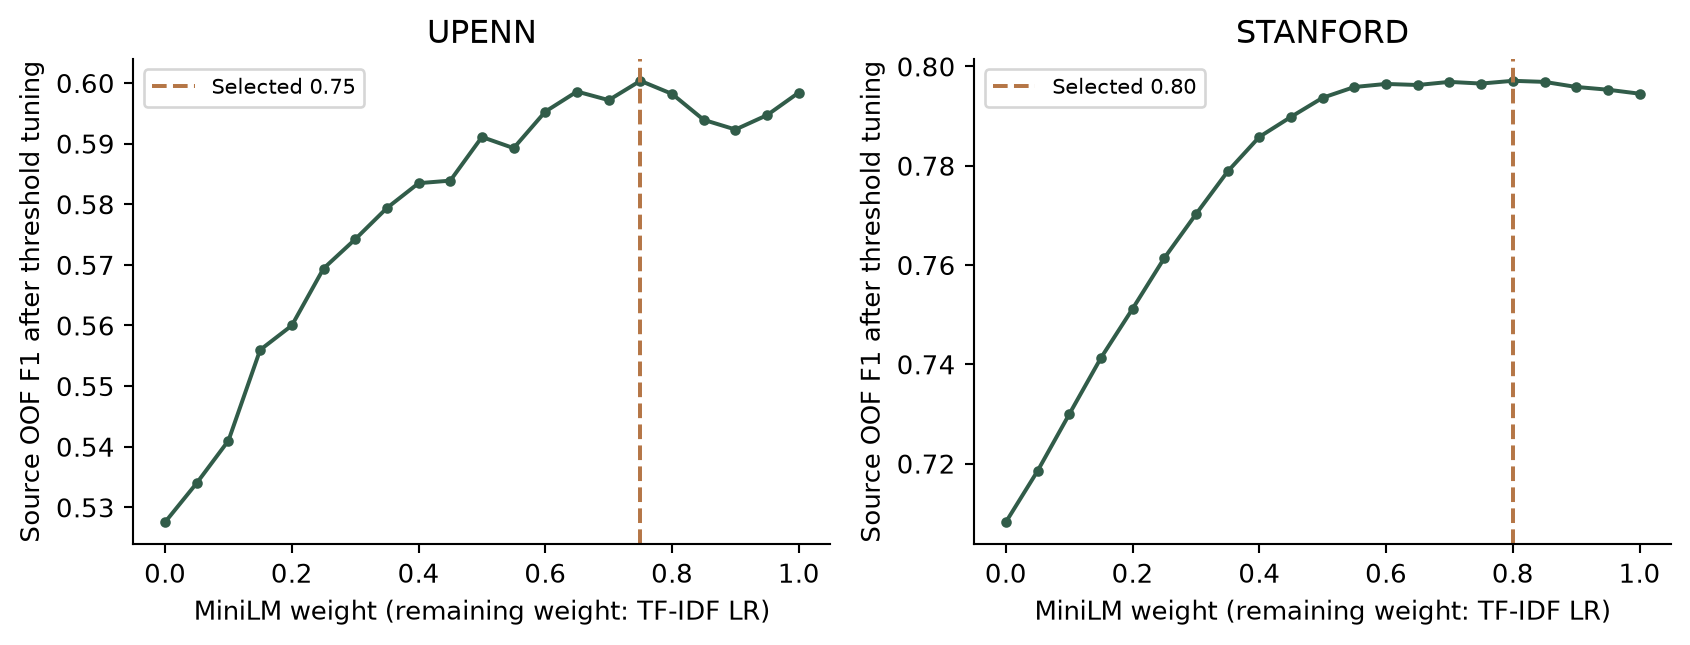

In [7]:
for script in ['blend_trained_models.py','package_blended_models.py']:
    subprocess.run([sys.executable,str(PROJECT/'scripts'/script)],cwd=PROJECT,check=True)
fine=json.loads((PROJECT/'reports/fine_tuning/results.json').read_text())
results=json.loads((PROJECT/'reports/ensembles/results.json').read_text())
for row in results:
    before=next(r for r in fine if r['train_source']==row['train_source'] and r['test_source']==row['test_source'])
    print(f"{row['train_source']} → {row['test_source']}: MiniLM={before['f1']:.4f}, blend={row['f1']:.4f}, delta={row['f1']-before['f1']:+.4f}, weight={row['minilm_weight']:.2f}, threshold={row['threshold']:.4f}")
    print('Precision:',row['precision'],'Recall:',row['recall'],'Confusion:',row['confusion_matrix'])
display(Image(filename=str(PROJECT/'reports/figures/blend_oof_search.png')))


## Nhập câu mới và tải model

Sửa TEXT_TO_PREDICT để thử. Mỗi thư mục hybrid chứa đủ weights, tokenizer, LR và predict.py.


In [8]:
TEXT_TO_PREDICT='I cannot submit my assignment and the deadline is tonight. Please help!'
subprocess.run([sys.executable,str(PROJECT/'models/urgency_hybrid_stanford/predict.py'),'--text',TEXT_TO_PREDICT],check=True)
from zipfile import ZipFile,ZIP_DEFLATED
archive=PROJECT/'urgency_hybrid_and_statistics.zip'
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for folder in [PROJECT/'models/urgency_hybrid_upenn',PROJECT/'models/urgency_hybrid_stanford',PROJECT/'reports/ensembles']:
        for file in folder.rglob('*'):
            if file.is_file():z.write(file,str(file.relative_to(PROJECT)))
    z.write(PROJECT/'reports/figures/blend_oof_search.png','reports/figures/blend_oof_search.png')
print('Download:',archive)


{
  "text": "I cannot submit my assignment and the deadline is tonight. Please help!",
  "score": 0.9736286113963777,
  "threshold": 0.3931987027552757,
  "urgent": true,
  "label": "URGENT",
  "minilm_score": 0.9745758175849915,
  "tfidf_score": 0.9698397866419225
}


Download: /Users/nhaterik/lastyear/machine/Project/urgency_hybrid_and_statistics.zip
